# BMI 데이터를 이용해서 머신러닝 전체 과정을 이해해보자

# 문제 정의
- 500명의 키와, 몸무게, 비만도 특성을 이용해서 비만 정도를 판단하는 모델을 만들어보자. 

# 데이터 수집
- bmi_500.csv 파일 불러오기

In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [5]:
data = pd.read_csv('data/bmi_500.csv')

In [6]:
data

,Gender,Height,Weight,Label
0,Male,174,96,Obesity
1,Male,189,87,Normal
2,Female,185,110,Obesity
3,Female,195,104,Overweight
4,Male,149,61,Overweight
...,...,...,...,...
495,Female,150,153,Extreme Obesity
496,Female,184,121,Obesity
497,Female,141,136,Extreme Obesity
498,Male,150,95,Extreme Obesity


# 데이터 전처리
- 정제된 데이터 활용했기 때문에 별도의 전처리 과정 X

# 탐색적 데이터 분석(EDA)
- 데이터 특성
- 정보 확인, 기술통계, 시각화
- 데이터 분리(문제/정답, 훈련/테스트)

In [8]:
# 결측치 확인
data.isnull()

,Gender,Height,Weight,Label
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
495,False,False,False,False
496,False,False,False,False
497,False,False,False,False
498,False,False,False,False


In [7]:
# 정보 확인
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Gender  500 non-null    object
 1   Height  500 non-null    int64 
 2   Weight  500 non-null    int64 
 3   Label   500 non-null    object
dtypes: int64(2), object(2)
memory usage: 15.8+ KB


In [9]:
# 기술 통계 분석
data.describe()
# 기본적으로 수치형(int, float) 데이터 타입에 대한 기술통계분석만 실행
# mean과 50%(중간값) 사이에 차이가 크다 == 데이터 속에 이상치가 있다

,Height,Weight
count,500.000000,500.000000
mean,169.944000,106.000000
std,16.375261,32.382607
min,140.000000,50.000000
25%,156.000000,80.000000
50%,170.500000,106.000000
75%,184.000000,136.000000
max,199.000000,160.000000


In [10]:
# 문자형 데이터의 기술통계 분석 (include = 'object' or 'all')
data.describe(include='object')

,Gender,Label
count,500,500
unique,2,6
top,Female,Extreme Obesity
freq,255,198


In [11]:
data

,Gender,Height,Weight,Label
0,Male,174,96,Obesity
1,Male,189,87,Normal
2,Female,185,110,Obesity
3,Female,195,104,Overweight
4,Male,149,61,Overweight
...,...,...,...,...
495,Female,150,153,Extreme Obesity
496,Female,184,121,Obesity
497,Female,141,136,Extreme Obesity
498,Male,150,95,Extreme Obesity


In [16]:
#문제/정답 데이터 분리
# 문제 : x (Height, Weight 추출)
# 정답 : y (label 추출)
x = data.iloc[:, 1:3]
x
#Height Weight
y = data['Label'] 

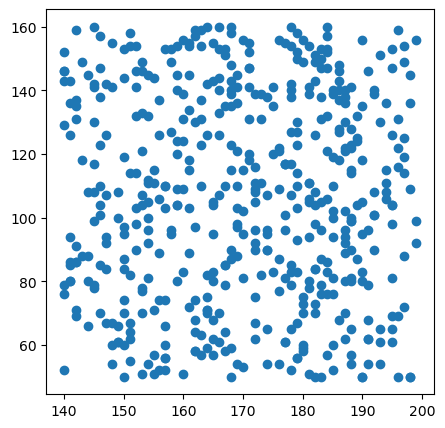

In [19]:
# 데이터 시각화
# 산점도 그래프 시각화
# 키와 몸무게의 분포 정도 확인
plt.figure(figsize=(5,5))
plt.scatter(data['Height'], data['Weight'])
plt.show()

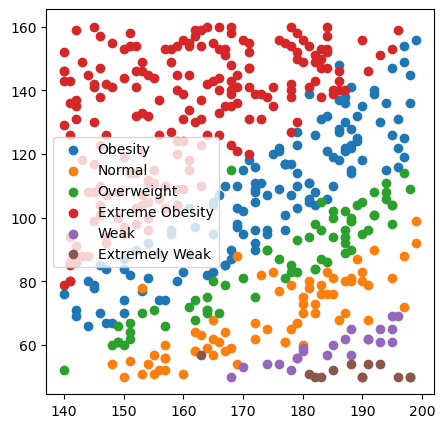

In [49]:
# Label 컬럼에서 Obesity
data_ob = data[data['Label'] == 'Obesity']
i = 'Obesity'
#i = data[data['Label'] == 'Obesity']
plt.figure(figsize=(5,5))
for i in data['Label'].unique() :
    plt.scatter(data[data['Label'] == i]['Height'], data[data['Label'] == i]['Weight'], label=i)
    
plt.legend()    
plt.show()

In [50]:
# 훈련데이터/테스트데이터 분리
# 자동으로 분리해주는 도구(train_test_split)
from sklearn.model_selection import train_test_split

In [54]:
#훈련/테스트 데이터 분리 후 순서에 맞게 변수에 담아주기
x_train, x_test, y_train, y_test = train_test_split(
    x,y, #원본데이터(문제, 정답)
    test_size = 0.3, # 나누고 싶은 테스트 데이터의 비율
    random_state = 42, # 랜덤 데이터의 규칙을 고정
    stratify = y # 결과값이 범주형(분류모델)일 때, 훈련/테스트 클래스 비율 동일
)

In [55]:
print('훈련:', x_train.shape, y_train.shape)
print('테스트', x_test.shape, y_test.shape)

훈련: (350, 2) (350,)
테스트 (150, 2) (150,)


# 모델 선택, 하이퍼파라미터 조정
- 모델 도구 불러오기(sckit-learn)
- 모델 객체 생성(하이퍼파라미터 조정)
- 모델 생성

In [56]:
# 모델 불러오기
from sklearn.neighbors import KNeighborsClassifier

In [57]:
# 모델 객체 생성
knn = KNeighborsClassifier(n_neighbors=7)

# 모델 학습
- fit

In [58]:
# 학습 model.fit(데이터)
knn.fit(x_train, y_train)

,n_neighbors,7
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


# 모델 평가
- score

In [59]:
# 모델 평가 model.score(데이터)
knn.score(x_test, y_test)

0.8666666666666667

In [60]:
knn.score(x_train, y_train)

0.9342857142857143

# 모델 복잡도 곡선 그리기

In [61]:
# 1. 모델 객체 생성 ~ 모델 평가
# 2. 반복문 k값을 1 ~ 50까지 반복
# 3. 빈 리스트 score 결과 담기

test_list = []
train_list = []

for i in range(1, 51, 1):
    #모델 객체 생성
    knn_model = KNeighborsClassifier(n_neighbors=i)
    
    #모델 학습
    knn_model.fit(x_train, y_train)
    
    #모델 평가
    train_list.append(knn_model.score(x_train, y_train))
    test_list.append(knn_model.score(x_test, y_test))


In [62]:
test_list

[0.88,
 0.8466666666666667,
 0.86,
 0.8666666666666667,
 0.8733333333333333,
 0.8666666666666667,
 0.8666666666666667,
 0.86,
 0.8733333333333333,
 0.9,
 0.9133333333333333,
 0.8733333333333333,
 0.88,
 0.8533333333333334,
 0.8466666666666667,
 0.84,
 0.8333333333333334,
 0.8133333333333334,
 0.7866666666666666,
 0.78,
 0.7933333333333333,
 0.7866666666666666,
 0.7933333333333333,
 0.7933333333333333,
 0.8066666666666666,
 0.7933333333333333,
 0.7866666666666666,
 0.7933333333333333,
 0.7866666666666666,
 0.78,
 0.7733333333333333,
 0.7866666666666666,
 0.78,
 0.7866666666666666,
 0.7866666666666666,
 0.78,
 0.7733333333333333,
 0.78,
 0.76,
 0.7666666666666667,
 0.7466666666666667,
 0.7466666666666667,
 0.7466666666666667,
 0.7466666666666667,
 0.7533333333333333,
 0.7333333333333333,
 0.7466666666666667,
 0.74,
 0.74,
 0.7333333333333333]

In [63]:
train_list

[1.0,
 0.9457142857142857,
 0.9514285714285714,
 0.9342857142857143,
 0.9428571428571428,
 0.9314285714285714,
 0.9342857142857143,
 0.92,
 0.9342857142857143,
 0.9428571428571428,
 0.9114285714285715,
 0.92,
 0.9142857142857143,
 0.9,
 0.8971428571428571,
 0.8885714285714286,
 0.8885714285714286,
 0.8628571428571429,
 0.8628571428571429,
 0.86,
 0.86,
 0.8542857142857143,
 0.8542857142857143,
 0.8457142857142858,
 0.8485714285714285,
 0.8457142857142858,
 0.8514285714285714,
 0.8514285714285714,
 0.8371428571428572,
 0.8371428571428572,
 0.8342857142857143,
 0.8228571428571428,
 0.8314285714285714,
 0.8285714285714286,
 0.8257142857142857,
 0.8257142857142857,
 0.8342857142857143,
 0.8171428571428572,
 0.8142857142857143,
 0.8114285714285714,
 0.8257142857142857,
 0.8114285714285714,
 0.8085714285714286,
 0.8085714285714286,
 0.8085714285714286,
 0.8028571428571428,
 0.8085714285714286,
 0.8057142857142857,
 0.8028571428571428,
 0.7971428571428572]

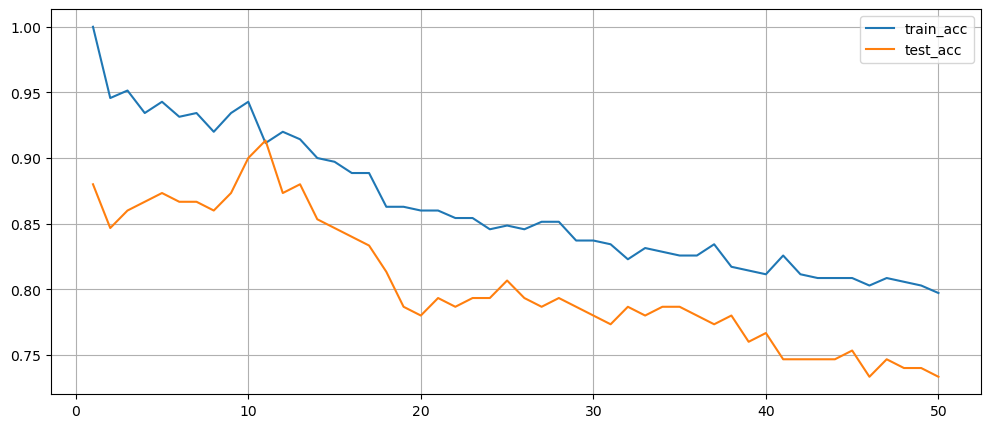

In [66]:
# 그래프 그리기
plt.figure(figsize=(12,5))

# 선 그래프
plt.plot(range(1, 51), train_list, label = 'train_acc')
plt.plot(range(1, 51), test_list, label = 'test_acc')


plt.grid() # 눈금선 표시
plt.legend() # 범례값 표시
plt.show()


In [68]:
# knn_11 모델 생성 및 학습
knn_11 = KNeighborsClassifier(n_neighbors=11)
knn_11.fit(x_train, y_train)
knn_11.predict([[173, 75]])

C:\Users\smart\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array(['Normal'], dtype=object)

In [69]:
# [[173, 75]] -> 모델이 학습한 형태와 다르기 때문에 경고가 발생함.
# 예측 데이터와 학습 데이터 형태로 맞춰줘야함.
my_test = pd.DataFrame([[173, 75]], columns=x_train.columns)
my_test

,Height,Weight
0,173,75


In [70]:
knn_11.predict(my_test)

array(['Normal'], dtype=object)